# Predicting Weekly Work Hours with Neural Networks
## ANA500 Micro-Project 4
Douglas Bobeck | October 11, 2026

Python code and output in Jupyter Notebook. This project continues Micro-Project 3 and completes Acquire, Prepare, Analyze, Report, and Act.

[Repository and submission files](https://github.com/mascon0423/ANA500/tree/main/week4) | [This notebook](https://github.com/mascon0423/ANA500/blob/main/week4/Micro_Project_4.ipynb)

## Results at a glance
Cross-validation selected MLP - expanded. On the same 6,513 test records as Week 3, its RMSE was 10.65 hours, MAE was 7.25 hours, and R-squared was 0.259. The preferred neural model was MLP - expanded, with test RMSE 10.65 hours, 2.2% lower than Week 3's SVR. The CV-selected method also had the lowest test RMSE. Performance at short and long workweeks still needs attention; average error alone is insufficient for individual decisions.

## Problem statement and hypothesis
Week 3's SVR improved average prediction error, but it overpredicted short workweeks and underpredicted long ones. Can neural networks and additional demographic information improve these weekly work-hour predictions?

My hypothesis is that a neural network using age, education, occupation, workclass, marital status, relationship, and sex can improve on Week 3's four-feature SVR. Additional context and nonlinear relationships may help explain differences in work hours. Full support requires lower test RMSE overall and lower MAE in both the under-35 and over-40 hour groups. Partial improvements will be reported separately.

I include a recurrent neural network (RNN) to address the assignment instruction. A multilayer perceptron (MLP), also called a dense feedforward network, is a natural comparison for records with no time sequence. The model ranking is determined by the results, not assumed in advance.

## Methods and assumptions
The source, outcome, original training/test split, and three grouped cross-validation folds match Week 3. Exact repeated full profiles stay together. Settings and the preferred model are chosen with training cross-validation, before this run evaluates test results. Each neural model uses a separate inner stopping split within a fold's training portion; the outer validation fold never chooses the stopping epoch.

The earlier test results and error groups have already informed this follow-up. The same test records allow an internal comparison, but they are not a new independent validation sample. One split, one initialization seed, and a limited parameter search do not establish a universally best architecture. Records are unweighted and describe the historical sample, not today's population.

## Acquire
### 1. Load packages and the unchanged source
Use the same Adult CSV as Week 3. Its 32,561 records come from the UCI training sample of the 1994 Census database. The input checksum fixes the source and row order. All analysis outputs stay in this notebook's folder. PyTorch runs on the CPU; no API key is required.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
%matplotlib inline

HERE = Path.cwd()
if (HERE / "week4" / "Micro_Project_4.ipynb").is_file():
    HERE = HERE / "week4"
assert (HERE / "adult_income.csv").is_file(), "Open the notebook beside adult_income.csv."
OUT = HERE / "outputs"
OUT.mkdir(exist_ok=True)
SEED, MAX_EPOCHS, PATIENCE, BATCH_SIZE = 42, 60, 8, 256
LEARNING_RATE, WEIGHT_DECAY = 0.001, 0.001
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
np.random.seed(SEED)
torch.manual_seed(SEED)
versions = {"Python": platform.python_version(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "Matplotlib": matplotlib.__version__,
            "scikit-learn": sklearn.__version__, "PyTorch": torch.__version__}
source_hash = hashlib.sha256((HERE / "adult_income.csv").read_bytes()).hexdigest()
assert source_hash == "f2c62076f19504d99a38b22badf445a7f42530ade6b827acf78dd143fbce38bb"
raw = pd.read_csv(HERE / "adult_income.csv", dtype="string", keep_default_na=False)
reference = json.loads((HERE / "week3_reference.json").read_text())
display(pd.DataFrame(versions.items(), columns=["Package", "Version"]))
print(f"Unchanged source: {len(raw):,} records; SHA-256: {source_hash}")

,Package,Version
0,Python,3.11.5
1,NumPy,1.26.4
2,Pandas,2.2.2
3,Matplotlib,3.8.4
4,scikit-learn,1.4.2
5,PyTorch,2.6.0


Unchanged source: 32,561 records; SHA-256: f2c62076f19504d99a38b22badf445a7f42530ade6b827acf78dd143fbce38bb


### 2. Validate the source
Trim spaces, identify missing fields, and check numerical ranges and education codes. Retain all records, valid extreme work hours, and 24 repeated full profiles. There is no person identifier proving that repeated profiles are erroneous duplicates.

In [2]:
columns = ("age workclass fnlwgt education education-num marital-status occupation "
           "relationship race sex capital-gain capital-loss hours-per-week "
           "native-country income").split()
assert list(raw.columns) == columns and raw.shape == (32561, 15)
data = raw.copy(deep=True)
for column in columns:
    data[column] = data[column].str.strip().replace({"?": pd.NA, "": pd.NA})
missing = data.isna().sum()
numeric = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
for column in numeric:
    values = pd.to_numeric(data[column], errors="raise")
    assert np.isfinite(values).all() and (values % 1 == 0).all()
    data[column] = values.astype("int64")
assert ((data[numeric].to_numpy() >= [17, 1, 1, 0, 0, 1]) &
        (data[numeric].to_numpy() <= [120, np.inf, 16, np.inf, np.inf, 168])).all()
education_codes = dict(zip([
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters",
    "Prof-school", "Doctorate"], range(1, 17)))
assert data["education"].map(education_codes).eq(data["education-num"]).all()
assert data["sex"].isin(["Female", "Male"]).all()
assert data["income"].isin(["<=50K", ">50K"]).all()
assert int(data.duplicated().sum()) == 24 and int(data.isna().any(axis=1).sum()) == 2399
display(missing[missing > 0].rename("Missing records").to_frame())
print("All 32,561 records retained; original numerical age and hours preserved.")

,Missing records
workclass,1836
occupation,1843
native-country,583


All 32,561 records retained; original numerical age and hours preserved.


## Prepare
### 3. Preserve Week 3's evaluation framework
The original four predictors are age, education, occupation, and workclass. The expanded set adds marital status, relationship, and sex as recorded in the historical source. These fields may capture household and demographic associations, not causal effects. Sex is represented by the source's two categories, which do not describe all identities. These models are for analysis, not individual employment decisions.

Income, survey weight, duplicate education codes, and the outcome or its grouped versions are excluded from predictors. Missing workclass and occupation become Unknown. Original numerical age and hours stay continuous. Save row membership and fold labels so the comparison is inspectable.

In [3]:
CORE = ["age", "education", "occupation", "workclass"]
EXPANDED = CORE + ["marital-status", "relationship", "sex"]
FEATURES = {"Core": CORE, "Expanded": EXPANDED}
X = data[EXPANDED].copy()
X[EXPANDED[1:]] = X[EXPANDED[1:]].fillna("Unknown").astype(str)
y = data["hours-per-week"].astype(float)
profile_groups = data.groupby(list(data.columns), dropna=False, sort=False).ngroup()
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
    random_state=SEED).split(X, y, groups=profile_groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
train_groups = profile_groups.iloc[train_idx]
folds = list(GroupKFold(n_splits=3).split(X_train, y_train, train_groups))
assert (len(train_idx), len(test_idx)) == (26048, 6513)
assert not set(train_groups) & set(profile_groups.iloc[test_idx])
membership = pd.DataFrame({"source_row": np.arange(len(data)),
    "profile_group": profile_groups, "partition": "test", "validation_fold": 0})
membership.loc[train_idx, "partition"] = "train"
for fold, (fit_ids, valid_ids) in enumerate(folds, 1):
    assert not set(train_groups.iloc[fit_ids]) & set(train_groups.iloc[valid_ids])
    membership.loc[train_idx[valid_ids], "validation_fold"] = fold
membership.to_csv(OUT / "split_membership.csv", index=False)
display(pd.DataFrame({"Partition": ["Training", "Test"],
    "Records": [len(train_idx), len(test_idx)]}))
print("Three shared grouped CV folds; full-profile groups cannot cross partitions.")

,Partition,Records
0,Training,26048
1,Test,6513


Three shared grouped CV folds; full-profile groups cannot cross partitions.


### 4. Inspect the work-hour distribution
Use training records to describe the outcome. The large concentration near 40 hours helps explain why average performance can hide poor predictions at the extremes. The diagnostic groups match Week 3: under 35, 35-40, and over 40 hours.

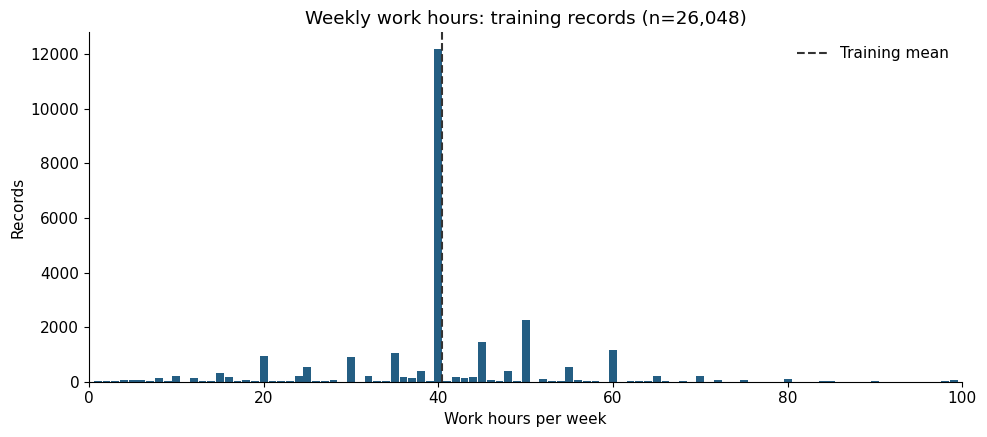

Training records at 40 hours: 46.8%.


In [4]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "figure.figsize": (10, 4.5), "savefig.dpi": 160})
COLORS = {"SVR": "#666666", "MLP": "#245E83", "RNN": "#AA6520"}
counts = y_train.value_counts().sort_index()
fig, ax = plt.subplots()
ax.bar(counts.index, counts.values, width=0.9, color="#245E83")
ax.axvline(y_train.mean(), color="#333333", linestyle="--", label="Training mean")
ax.set(title=f"Weekly work hours: training records (n={len(y_train):,})",
       xlabel="Work hours per week", ylabel="Records", xlim=(0, 100))
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(OUT / "01_training_hours.png"); plt.show()
print(f"Training records at 40 hours: {100*y_train.eq(40).mean():.1f}%.")

## Analyze
### 5. Define preprocessing and reproduce the traditional comparisons
Every pipeline fits age scaling and category encoding only on its training portion. The original models use Week 3's selected settings; their cross-validation scores are checked against the saved Week 3 reference. The expanded SVR searches the same four C/epsilon combinations used in Week 3. It provides a control for improvements from additional features.

SVR is the regression form of a support vector machine. RMSE is measured in work hours; lower is better. Fold standard deviation describes variation across the three folds and is not a confidence interval.

In [5]:
def prepare(features):
    return ColumnTransformer([
        ("age", StandardScaler(), ["age"]),
        ("categories", OneHotEncoder(drop="first", handle_unknown="ignore",
                                     sparse_output=False), features[1:])])

def metrics(actual, predicted):
    actual, predicted = np.asarray(actual, dtype=float), np.asarray(predicted, dtype=float)
    error = predicted - actual
    return {"MAE": float(np.abs(error).mean()), "RMSE": float(np.sqrt(np.mean(error**2))),
            "R-squared": float(1 - np.sum(error**2) / np.sum((actual-actual.mean())**2))}

traditional_specs = {
    "Mean baseline": ("Core", DummyRegressor(strategy="mean"), {}),
    "Linear - core": ("Core", LinearRegression(), {}),
    "SVR - core": ("Core", SVR(C=10, epsilon=2, cache_size=512), {}),
    "Tree - core": ("Core", DecisionTreeRegressor(max_depth=8, min_samples_leaf=25,
                                                 random_state=SEED), {}),
    "SVR - expanded": ("Expanded", SVR(cache_size=512),
                       {"model__C": [1.0, 10.0], "model__epsilon": [0.5, 2.0]})}
traditional, cv_rows, settings = {}, [], {}
for name, (feature_set, model, grid) in traditional_specs.items():
    features = FEATURES[feature_set]
    pipeline = Pipeline([("prepare", prepare(features)), ("model", model)])
    search = GridSearchCV(pipeline, grid, cv=folds, scoring="neg_root_mean_squared_error",
                          n_jobs=1, refit=True, error_score="raise")
    search.fit(X_train[features], y_train)
    traditional[name] = search.best_estimator_
    best = search.best_index_
    cv_rows.append({"Model": name, "Features": feature_set,
        "CV RMSE": -search.best_score_, "Fold SD": search.cv_results_["std_test_score"][best]})
    settings[name] = search.best_params_ or str(model)
    print(f"{name}: CV RMSE {-search.best_score_:.3f}")
reference_names = ["Mean baseline", "Linear regression", "Support vector regression", "Decision tree regression"]
for row, old_name in zip(cv_rows[:4], reference_names):
    old = next(r for r in reference["comparison"] if r["Model"] == old_name)
    np.testing.assert_allclose(row["CV RMSE"], old["CV RMSE"], rtol=1e-8)
display(pd.DataFrame(cv_rows).round(3))

Mean baseline: CV RMSE 12.340
Linear - core: CV RMSE 11.542


SVR - core: CV RMSE 10.926
Tree - core: CV RMSE 11.021


SVR - expanded: CV RMSE 10.707


,Model,Features,CV RMSE,Fold SD
0,Mean baseline,Core,12.340,0.240
1,Linear - core,Core,11.542,0.199
2,SVR - core,Core,10.926,0.187
3,Tree - core,Core,11.021,0.167
4,SVR - expanded,Expanded,10.707,0.166


### 6. Represent the same information for each neural network
The MLP receives one vector containing scaled age and encoded categories. The RNN receives one feature at a time for the same person. Each step contains that field's encoded values, zero padding to a common width, and a field identifier. The identifier distinguishes fields when their numerical values happen to match. The sequence length is four or seven fields, not four or seven people.

The default order is the feature list above. It is an artificial feature order, not time. The RNN starts a new hidden state for every person. A later check retrains the preferred RNN with reversed and shuffled field orders while retaining field identity. This is an experimental use of recurrence on tabular data.

In [6]:
def neural_inputs(transformer, frame, features, kind, order=None):
    values = transformer.transform(frame[features]).astype(np.float32)
    if kind == "MLP":
        return torch.from_numpy(values)
    encoder = transformer.named_transformers_["categories"]
    widths = [1] + [len(c)-1 for c in encoder.categories_]
    assert sum(widths) == values.shape[1]
    width, fields = max(widths), len(features)
    tokens = np.zeros((len(frame), fields, width + fields), dtype=np.float32)
    start = 0
    for field, size in enumerate(widths):
        tokens[:, field, :size] = values[:, start:start+size]
        tokens[:, field, width+field] = 1.0
        start += size
    # Reorder whole field tokens, including their identities; never reorder people.
    if order is not None:
        assert sorted(order) == list(range(fields))
        tokens = tokens[:, order, :].copy()
    return torch.from_numpy(tokens)

class WorkHoursNet(nn.Module):
    """Two hidden MLP layers, or two recurrent layers followed by a dense layer."""
    def __init__(self, kind, input_size, size):
        super().__init__()
        self.kind = kind
        if kind == "MLP":
            self.head = nn.Sequential(nn.Linear(input_size, size), nn.ReLU(),
                nn.Linear(size, size//2), nn.ReLU(), nn.Linear(size//2, 1))
        else:
            self.recurrent = nn.RNN(input_size, size, num_layers=2, batch_first=True)
            self.head = nn.Sequential(nn.Linear(size, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, inputs):
        if self.kind == "RNN":
            sequence, _ = self.recurrent(inputs)
            inputs = sequence[:, -1, :]
        return self.head(inputs).squeeze(1)

def predict_net(model, inputs, mean, sd):
    model.eval()
    with torch.no_grad():
        return model(inputs).numpy().astype(float) * sd + mean

### 7. Train with a separate stopping set
Both neural families use Adam, learning rate 0.001, weight decay 0.001, batches of 256, gradient clipping at 1, seed 42, and squared-error loss on standardized work hours. MLP candidates have 32/16 or 64/32 hidden units. RNN candidates have two recurrent layers of 16 or 32 units and a 16-unit dense layer.

Inside each cross-validation training portion, a grouped 80/20 split chooses the stopping epoch, up to 60 epochs with patience 8. Preprocessing and outcome scaling are fitted only on the inner fit portion at that stage. Then a fresh model and transformer fit the whole outer training portion for that fixed number of epochs before the outer fold is scored. This prevents the scored fold from choosing its own stopping point.

Final models use the median stopping epoch from the three folds for the selected size, and then fit all 26,048 training records. No test values choose settings, epochs, or the preferred method.

In [7]:
def fit_net(kind, size, features, fit_frame, fit_y, *, epochs=MAX_EPOCHS,
            stop_frame=None, stop_y=None, order=None):
    transformer = prepare(features).fit(fit_frame[features])
    inputs = neural_inputs(transformer, fit_frame, features, kind, order)
    mean, sd = float(np.mean(fit_y)), float(np.std(fit_y))
    assert sd > 0
    target = torch.tensor((np.asarray(fit_y)-mean)/sd, dtype=torch.float32)
    torch.manual_seed(SEED)
    model = WorkHoursNet(kind, inputs.shape[-1], size)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    generator = torch.Generator().manual_seed(SEED)
    loss_function = nn.MSELoss()
    best_rmse, patience_reference, stale, best_epoch = np.inf, np.inf, 0, epochs
    learning = []
    if stop_frame is not None:
        stop_inputs = neural_inputs(transformer, stop_frame, features, kind, order)
    for epoch in range(1, epochs+1):
        model.train()
        for ids in torch.randperm(len(inputs), generator=generator).split(BATCH_SIZE):
            optimizer.zero_grad()
            loss = loss_function(model(inputs[ids]), target[ids])
            assert torch.isfinite(loss), "Nonfinite training loss."
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
        if stop_frame is not None:
            score = metrics(stop_y, predict_net(model, stop_inputs, mean, sd))["RMSE"]
            learning.append({"Epoch": epoch, "Inner stopping RMSE": score})
            if score < best_rmse:
                best_rmse, best_epoch = score, epoch
            if score < patience_reference - 0.001:
                patience_reference, stale = score, 0
            else:
                stale += 1
            if stale >= PATIENCE:
                break
    # Inner-run weights are discarded; only their chosen epoch is carried forward.
    return model, transformer, mean, sd, best_epoch, learning

def predict_bundle(bundle, frame, features, kind, order=None):
    model, transformer, mean, sd = bundle[:4]
    return predict_net(model, neural_inputs(transformer, frame, features, kind, order), mean, sd)

### 8. Compare neural candidates on the shared folds
Candidate sizes and feature sets are fixed before examining new test predictions. Compare the mean of three outer-fold RMSE values, exactly as in Week 3. The expanded feature set changes the available information, so the expanded SVR is necessary when interpreting gains. Search effort and architecture sizes differ; this is a limited model comparison, not proof that one neural family is always superior.

In [8]:
candidate_rows, fold_rows, learning_rows = [], [], []
neural_choices, neural_models = {}, {}
for feature_set, features in FEATURES.items():
    for kind, sizes in [("MLP", [32, 64]), ("RNN", [16, 32])]:
        name = f"{kind} - {feature_set.lower()}"
        candidates = []
        for size in sizes:
            scores, chosen_epochs = [], []
            for fold, (fit_ids, valid_ids) in enumerate(folds, 1):
                inner_fit, inner_stop = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
                    random_state=SEED).split(X_train.iloc[fit_ids], y_train.iloc[fit_ids],
                                             train_groups.iloc[fit_ids]))
                fit_inner, stop_inner = fit_ids[inner_fit], fit_ids[inner_stop]
                assert not set(train_groups.iloc[fit_inner]) & set(train_groups.iloc[stop_inner])
                inner = fit_net(kind, size, features, X_train.iloc[fit_inner], y_train.iloc[fit_inner],
                    stop_frame=X_train.iloc[stop_inner], stop_y=y_train.iloc[stop_inner])
                epoch = inner[4]
                learning_rows.extend({"Model": name, "Size": size, "Fold": fold, **r} for r in inner[5])
                fitted = fit_net(kind, size, features, X_train.iloc[fit_ids], y_train.iloc[fit_ids], epochs=epoch)
                score = metrics(y_train.iloc[valid_ids],
                    predict_bundle(fitted, X_train.iloc[valid_ids], features, kind))["RMSE"]
                scores.append(score); chosen_epochs.append(epoch)
                fold_rows.append({"Model": name, "Size": size, "Fold": fold,
                                  "RMSE": score, "Epochs": epoch})
            row = {"Model": name, "Features": feature_set, "Size": size,
                   "CV RMSE": float(np.mean(scores)), "Fold SD": float(np.std(scores)),
                   "Final epochs": int(np.median(chosen_epochs))}
            candidates.append(row); candidate_rows.append(row)
            pd.DataFrame(candidate_rows).to_csv(OUT / "neural_candidates.csv", index=False)
            print(f"{name}, size {size}: CV RMSE {row['CV RMSE']:.3f}; final epochs {row['Final epochs']}")
        choice = min(candidates, key=lambda r: r["CV RMSE"])
        neural_choices[name] = choice
        cv_rows.append({k: choice[k] for k in ["Model", "Features", "CV RMSE", "Fold SD"]})
        settings[name] = {"size": choice["Size"], "epochs": choice["Final epochs"]}
        neural_models[name] = fit_net(kind, choice["Size"], features, X_train, y_train,
                                     epochs=choice["Final epochs"])
cv_table = pd.DataFrame(cv_rows)
selected = cv_table.loc[cv_table["CV RMSE"].idxmin(), "Model"]
selected_neural = cv_table[cv_table["Model"].isin(neural_models)].sort_values("CV RMSE").iloc[0]["Model"]
selected_rnn = cv_table[cv_table["Model"].str.startswith("RNN")].sort_values("CV RMSE").iloc[0]["Model"]
display(cv_table.sort_values("CV RMSE").round(3))
print("Preferred method fixed before test scoring:", selected)
print("Preferred neural model fixed before test scoring:", selected_neural)

MLP - core, size 32: CV RMSE 10.833; final epochs 33


MLP - core, size 64: CV RMSE 10.857; final epochs 13


RNN - core, size 16: CV RMSE 10.851; final epochs 37


RNN - core, size 32: CV RMSE 10.875; final epochs 14


MLP - expanded, size 32: CV RMSE 10.667; final epochs 19


MLP - expanded, size 64: CV RMSE 10.668; final epochs 15


RNN - expanded, size 16: CV RMSE 10.678; final epochs 38


RNN - expanded, size 32: CV RMSE 10.673; final epochs 37


,Model,Features,CV RMSE,Fold SD
7,MLP - expanded,Expanded,10.667,0.171
8,RNN - expanded,Expanded,10.673,0.154
4,SVR - expanded,Expanded,10.707,0.166
5,MLP - core,Core,10.833,0.182
6,RNN - core,Core,10.851,0.187
2,SVR - core,Core,10.926,0.187
3,Tree - core,Core,11.021,0.167
1,Linear - core,Core,11.542,0.199
0,Mean baseline,Core,12.340,0.240


Preferred method fixed before test scoring: MLP - expanded
Preferred neural model fixed before test scoring: MLP - expanded


### 9. Check RNN feature-order sensitivity using training folds
An RNN on these data depends on an imposed order. For the RNN feature set preferred by cross-validation, retrain the chosen size in reverse order and one seeded shuffled order. Keep each fold's canonical stopping epoch fixed, the same rows, and the same seed. No order is chosen from this diagnostic and no alternative-order model is evaluated on the test set. Differences can reflect optimization and encoding as well as architecture; this check cannot establish general inferiority.

In [9]:
rnn_choice = neural_choices[selected_rnn]
rnn_features = FEATURES[rnn_choice["Features"]]
field_count = len(rnn_features)
orders = {"Original": list(range(field_count)), "Reversed": list(reversed(range(field_count))),
          "Shuffled": np.random.default_rng(SEED).permutation(field_count).tolist()}
order_rows = []
for label, order in orders.items():
    scores = []
    for fold, (fit_ids, valid_ids) in enumerate(folds, 1):
        original = next(r for r in fold_rows if r["Model"] == selected_rnn and
                        r["Size"] == rnn_choice["Size"] and r["Fold"] == fold)
        if label == "Original":
            score = original["RMSE"]
        else:
            fitted = fit_net("RNN", rnn_choice["Size"], rnn_features,
                X_train.iloc[fit_ids], y_train.iloc[fit_ids], epochs=original["Epochs"], order=order)
            score = metrics(y_train.iloc[valid_ids],
                predict_bundle(fitted, X_train.iloc[valid_ids], rnn_features, "RNN", order))["RMSE"]
        scores.append(score)
    order_rows.append({"Order": label, "Fields": ", ".join(rnn_features[i] for i in order),
                       "CV RMSE": float(np.mean(scores)), "Fold SD": float(np.std(scores))})
order_table = pd.DataFrame(order_rows)
display(order_table[["Order", "CV RMSE", "Fold SD"]].round(3))
print("Sensitivity model:", selected_rnn, "; alternative orders do not change selection.")

,Order,CV RMSE,Fold SD
0,Original,10.673,0.154
1,Reversed,10.647,0.173
2,Shuffled,10.662,0.159


Sensitivity model: RNN - expanded ; alternative orders do not change selection.


## Report
### 10. Evaluate fixed models on the same test records
Report MAE, RMSE, and R-squared on all 6,513 test records. Model selection remains the earlier cross-validation choice even if the test ranking differs. The four original model results must reproduce Week 3. No neural settings are changed in response to this table.

In [10]:
predictions, test_rows = {}, []
for name, model in traditional.items():
    features = FEATURES[traditional_specs[name][0]]
    predictions[name] = model.predict(X_test[features])
for name, bundle in neural_models.items():
    choice = neural_choices[name]
    predictions[name] = predict_bundle(bundle, X_test, FEATURES[choice["Features"]], name.split()[0])
for name, predicted in predictions.items():
    assert len(predicted) == len(y_test) and np.isfinite(predicted).all()
    test_rows.append({"Model": name, **metrics(y_test, predicted)})
comparison = cv_table.merge(pd.DataFrame(test_rows), on="Model", validate="one_to_one")
for name, old_name in zip(list(traditional)[:4], reference_names):
    now = comparison.set_index("Model").loc[name]
    old = next(r for r in reference["comparison"] if r["Model"] == old_name)
    for metric in ["MAE", "RMSE", "R-squared"]:
        np.testing.assert_allclose(now[metric], old[metric], rtol=1e-8, atol=1e-10)
display(comparison[["Model", "CV RMSE", "MAE", "RMSE", "R-squared"]].round(3))
print("Preferred method remains:", selected)

,Model,CV RMSE,MAE,RMSE,R-squared
0,Mean baseline,12.340,7.607,12.371,-0.000
1,Linear - core,11.542,7.873,11.565,0.126
2,SVR - core,10.926,7.164,10.889,0.225
3,Tree - core,11.021,7.494,10.964,0.214
4,SVR - expanded,10.707,7.067,10.714,0.250
5,MLP - core,10.833,7.337,10.817,0.235
6,RNN - core,10.851,7.361,10.947,0.217
7,MLP - expanded,10.667,7.250,10.650,0.259
8,RNN - expanded,10.673,7.297,10.780,0.240


Preferred method remains: MLP - expanded


### 11. Compare overall errors and the effect of added features
Show every model's test RMSE, then compare core and expanded predictors within SVR, MLP, and RNN. These comparisons separate changes in features from changes in modeling method. Point estimates have no confidence intervals; small differences should be interpreted cautiously.

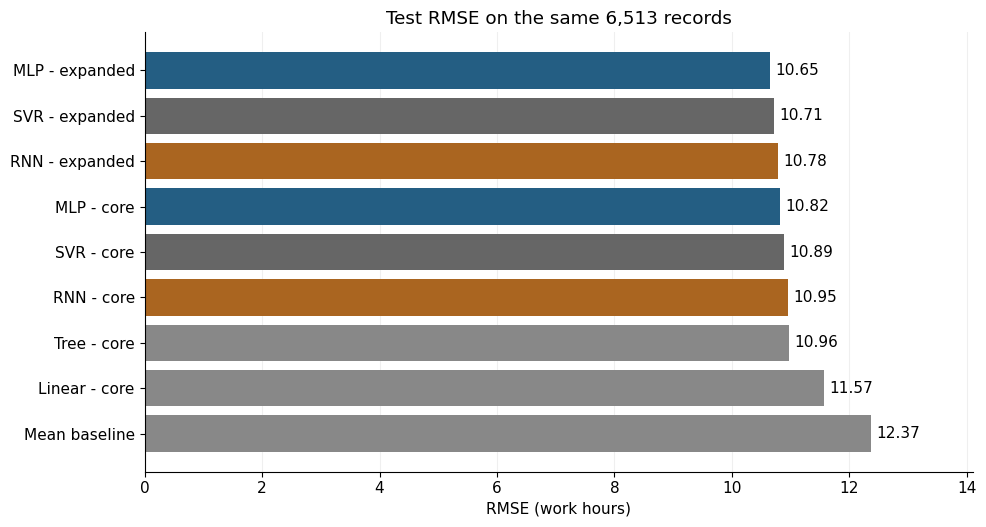

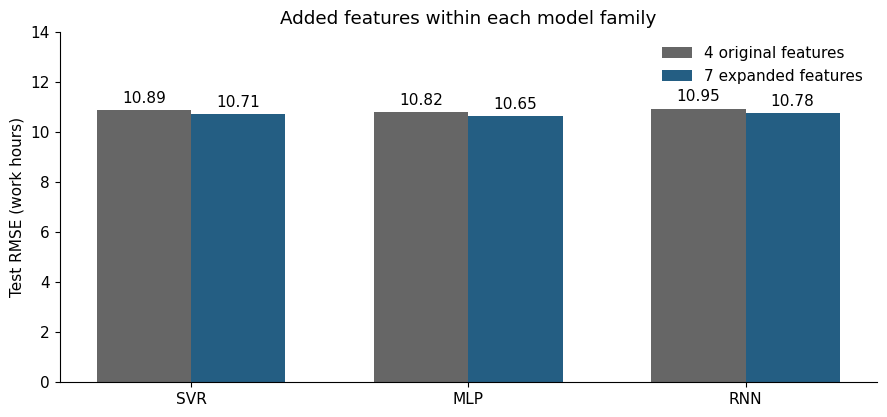

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.4))
ordered = comparison.sort_values("RMSE", ascending=False)
bar_colors = [COLORS.get(name.split()[0], "#888888") for name in ordered["Model"]]
bars = ax.barh(ordered["Model"], ordered["RMSE"], color=bar_colors)
ax.bar_label(bars, fmt="%.2f", padding=4)
ax.set(title="Test RMSE on the same 6,513 records", xlabel="RMSE (work hours)",
       xlim=(0, ordered["RMSE"].max()*1.14))
ax.grid(axis="x", alpha=0.2); ax.set_axisbelow(True); fig.tight_layout()
fig.savefig(OUT / "02_model_errors.png"); plt.show()

fig, ax = plt.subplots(figsize=(9, 4.3))
families = ["SVR", "MLP", "RNN"]
for j, label in enumerate(["core", "expanded"]):
    vals = [float(comparison.set_index("Model").loc[f"{n} - {label}", "RMSE"]) for n in families]
    bars = ax.bar(np.arange(3)+(j-0.5)*0.34, vals, width=0.34,
                  color=["#666666", "#245E83"][j], label=["4 original features", "7 expanded features"][j])
    ax.bar_label(bars, fmt="%.2f", padding=3)
ax.set(xticks=np.arange(3), xticklabels=families, ylabel="Test RMSE (work hours)",
       title="Added features within each model family", ylim=(0, 14))
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(OUT / "03_feature_comparison.png"); plt.show()

### 12. Investigate short and long workweeks
These groups are defined by actual test hours for error diagnosis only; they are never predictors. MAE measures the size of errors. Bias is predicted minus actual hours: positive values indicate overprediction and negative values indicate underprediction. Report all group sizes and the same boundaries used in Week 3.

,Model,Hours group,n,MAE,Bias
6,SVR - core,Under 35,1124,13.81,13.25
7,SVR - core,35-40,3418,2.75,0.73
8,SVR - core,Over 40,1971,11.02,-10.73
12,SVR - expanded,Under 35,1124,13.53,12.82
13,SVR - expanded,35-40,3418,3.01,0.79
14,SVR - expanded,Over 40,1971,10.43,-10.06
21,MLP - expanded,Under 35,1124,12.62,12.08
22,MLP - expanded,35-40,3418,3.73,0.48
23,MLP - expanded,Over 40,1971,10.29,-9.83
24,RNN - expanded,Under 35,1124,11.64,10.58


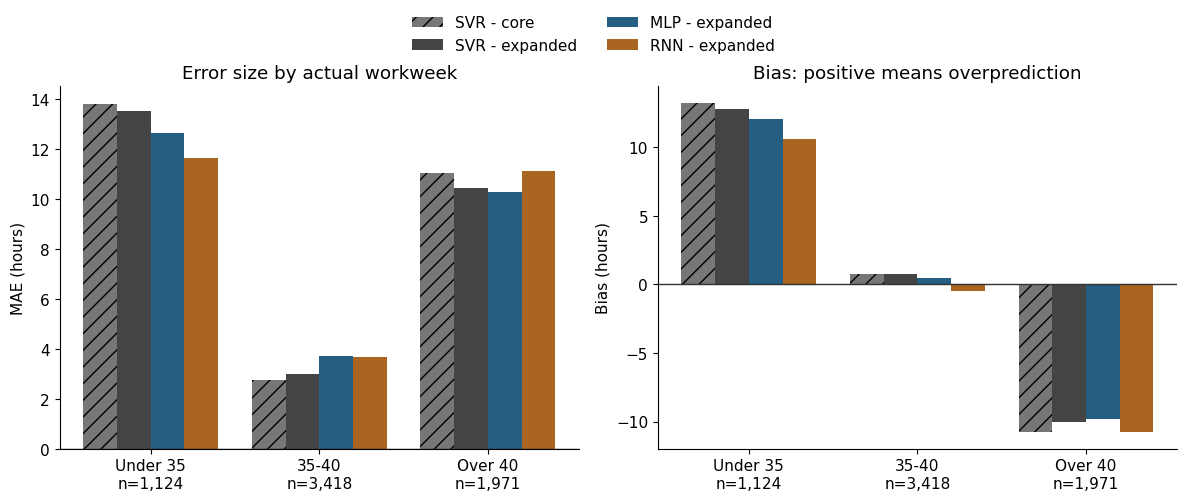

In [12]:
bands = pd.cut(y_test, bins=[0, 34, 40, np.inf], labels=["Under 35", "35-40", "Over 40"])
group_rows = []
for name, predicted in predictions.items():
    for label in bands.cat.categories:
        mask = np.asarray(bands == label)
        actual, pred = y_test.to_numpy()[mask], predicted[mask]
        group_rows.append({"Model": name, "Hours group": label, "n": int(mask.sum()),
            "Actual mean": float(actual.mean()), "Predicted mean": float(pred.mean()),
            "MAE": float(np.abs(pred-actual).mean()), "Bias": float((pred-actual).mean())})
group_table = pd.DataFrame(group_rows)
focus = ["SVR - core", "SVR - expanded", "MLP - expanded", "RNN - expanded"]
display(group_table[group_table["Model"].isin(focus)][["Model", "Hours group", "n", "MAE", "Bias"]].round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
labels = list(bands.cat.categories); x = np.arange(3)
for j, name in enumerate(focus):
    rows = group_table[group_table["Model"] == name].set_index("Hours group").loc[labels]
    color = ["#777777", "#444444", "#245E83", "#AA6520"][j]
    for ax, metric in zip(axes, ["MAE", "Bias"]):
        ax.bar(x+(j-1.5)*0.2, rows[metric], width=0.2, color=color, label=name,
               hatch="//" if j==0 else None)
        ax.set_xticks(x, [f"{label}\nn={int(rows.loc[label, 'n']):,}" for label in labels])
        ax.set_ylabel(f"{metric} (hours)"); ax.axhline(0, color="#333333", linewidth=0.8)
axes[0].set_title("Error size by actual workweek"); axes[1].set_title("Bias: positive means overprediction")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=2,
           frameon=False, bbox_to_anchor=(0.5, 1.10))
fig.tight_layout(); fig.savefig(OUT / "04_errors_by_workweek.png", bbox_inches="tight"); plt.show()

### 13. Inspect the preferred neural model and RNN sensitivity
Plot a reproducible sample of 500 test records to show how predictions relate to actual hours. The diagonal marks perfect prediction. The order chart reports training cross-validation results for the same RNN size and feature set; its axis starts at zero.

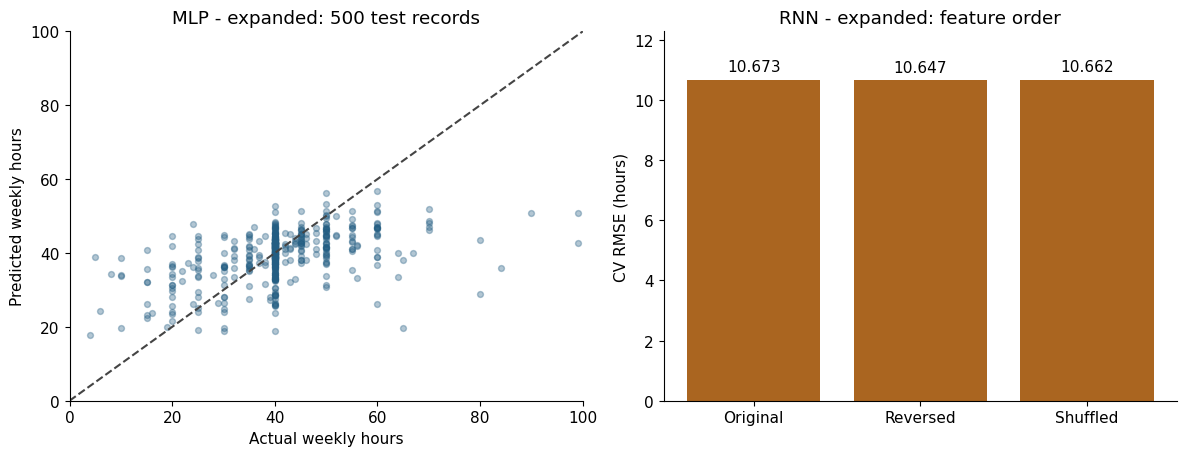

In [13]:
plot_ids = np.random.default_rng(SEED).choice(len(y_test), size=500, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].scatter(y_test.iloc[plot_ids], predictions[selected_neural][plot_ids],
                s=18, alpha=0.35, color="#245E83")
axes[0].plot([0, 100], [0, 100], "--", color="#444444")
axes[0].set(title=selected_neural+": 500 test records", xlabel="Actual weekly hours",
            ylabel="Predicted weekly hours", xlim=(0, 100), ylim=(0, 100))
bars = axes[1].bar(order_table["Order"], order_table["CV RMSE"], color="#AA6520")
axes[1].bar_label(bars, fmt="%.3f", padding=4)
axes[1].set(title=selected_rnn+": feature order", ylabel="CV RMSE (hours)",
            ylim=(0, order_table["CV RMSE"].max()*1.15))
fig.tight_layout(); fig.savefig(OUT / "05_neural_diagnostics.png"); plt.show()

## Act
### 14. Apply the selected method and assess the hypothesis
Apply the cross-validation-selected method to the first five test rows in source order. These are examples, not cases chosen for their accuracy. Compare the preferred neural model with Week 3's SVR for the stated hypothesis. A lower overall error does not by itself resolve poor predictions at the extremes.

In [14]:
examples = X_test[CORE].head(5).copy()
examples["Actual hours"] = y_test.iloc[:5].to_numpy()
examples["Predicted hours"] = predictions[selected][:5]
display(examples.round({"Predicted hours": 2}))
scores = comparison.set_index("Model")
neural_gain = 100*(scores.loc["SVR - core", "RMSE"]-scores.loc[selected_neural, "RMSE"])/scores.loc["SVR - core", "RMSE"]
group_index = group_table.set_index(["Model", "Hours group"])
hypothesis_checks = {"Lower overall RMSE": bool(scores.loc[selected_neural, "RMSE"] < scores.loc["SVR - core", "RMSE"])}
for label in ["Under 35", "Over 40"]:
    hypothesis_checks[f"Lower MAE: {label}"] = bool(group_index.loc[(selected_neural, label), "MAE"] <
                                                    group_index.loc[("SVR - core", label), "MAE"])
display(pd.DataFrame(hypothesis_checks.items(), columns=["Comparison with Week 3 SVR", "Supported"]))
display(Markdown(f"### Model choice\nCross-validation selected {selected}. Its test RMSE is "
    f"{scores.loc[selected, 'RMSE']:.2f} hours and MAE is {scores.loc[selected, 'MAE']:.2f} hours. "
    f"The preferred neural model is {selected_neural}; its test RMSE change versus Week 3 SVR "
    f"is {neural_gain:.1f}% lower (a negative value means worse)."))

,age,education,occupation,workclass,Actual hours,Predicted hours
6,49,9th,Other-service,Private,16.0,34.58
8,31,Masters,Prof-specialty,Private,50.0,40.92
30,23,Assoc-acdm,Protective-serv,Local-gov,52.0,41.27
33,30,Some-college,Adm-clerical,Federal-gov,40.0,43.45
34,22,Some-college,Other-service,State-gov,15.0,32.42


,Comparison with Week 3 SVR,Supported
0,Lower overall RMSE,True
1,Lower MAE: Under 35,True
2,Lower MAE: Over 40,True


### Model choice
Cross-validation selected MLP - expanded. Its test RMSE is 10.65 hours and MAE is 7.25 hours. The preferred neural model is MLP - expanded; its test RMSE change versus Week 3 SVR is 2.2% lower (a negative value means worse).

### Interpretation and next steps
I included an RNN to address the assignment instruction. With seven predictors, the MLP's test RMSE was 10.65 hours, lower than the RNN's 10.78 hours. The expanded SVR had RMSE 10.71 hours. The original four-feature SVR had RMSE 10.89 hours. Comparing both feature sets helps separate gains from additional information from gains associated with a different model.

For under 35 hours, MAE changed from 13.81 with Week 3 SVR to 12.62 with MLP - expanded (n=1,124). Mean bias changed from +13.25 to +12.08 hours. For over 40 hours, MAE changed from 11.02 with Week 3 SVR to 10.29 with MLP - expanded (n=1,971). Mean bias changed from -10.73 to -9.83 hours. The three stated criteria support the hypothesis on this test sample.

The MLP did not lead on every measure. Expanded RNN had lower MAE for short workweeks (11.64 versus 12.62 hours). Expanded SVR had lower overall MAE (7.07 versus 7.25 hours). RMSE was the selection criterion established before test scoring, so these tradeoffs inform the interpretation rather than change the selected model.

For RNN - expanded, the three tested field orders produced CV RMSE values from 10.647 to 10.673 hours. The reversed order's CV RMSE was slightly lower than the MLP's 10.667; this diagnostic was not used to choose another model or tested on the test set. The original-order MLP and RNN CV scores were also very close, so the results do not establish a decisive architecture advantage. The RNN processes an imposed field order rather than an observed time sequence. An MLP is a more direct representation of these tabular records, but representation alone does not establish which model will have the smallest error. The tested sizes, stopping choices, order, and initialization all affect the comparison.

This project illustrates why the data structure, the quantity being predicted, and validation results should guide model choice. Including a model because it is part of an assignment does not mean it must be the preferred method. I would retain the CV-selected method for further analysis and investigate missing information about short and long workweeks before expanding model complexity.

Historical unweighted data, overlapping household-related predictors, one split, a limited search, and one seed restrict general conclusions. Predictive associations do not establish causes. Outcome-defined groups are retrospective diagnostics and cannot identify a new person's actual workweek before it is observed. These models should not set individual schedules or employment decisions. Current independent data, fairness checks, repeated training seeds, and a defined acceptable error would be needed before operational use.

Step 5, Act, consists of applying the selected model to held-out examples and using the findings to decide what needs further investigation; it is not a live deployment.

### 15. Verify and save the analysis
Check source integrity, exact group separation, fold membership, preservation of Week 3 results, independent error calculations, and diagnostic totals. Saved tables contain every model, test prediction, candidate score, and RNN order comparison. The code and comments remain in this notebook.

In [15]:
assert hashlib.sha256((HERE / "adult_income.csv").read_bytes()).hexdigest() == source_hash
assert membership.groupby("profile_group")["partition"].nunique().max() == 1
assert membership[membership["partition"] == "train"].groupby("profile_group")["validation_fold"].nunique().max() == 1
assert membership["validation_fold"].value_counts().drop(0).sum() == len(train_idx)
for name, pred in predictions.items():
    actual = y_test.to_numpy()
    np.testing.assert_allclose(scores.loc[name, "MAE"], sum(abs(float(p)-float(a)) for p,a in zip(pred,actual))/len(actual))
    np.testing.assert_allclose(scores.loc[name, "RMSE"], (sum((float(p)-float(a))**2 for p,a in zip(pred,actual))/len(actual))**0.5)
    assert group_table.loc[group_table["Model"] == name, "n"].sum() == len(test_idx)
assert selected == cv_table.loc[cv_table["CV RMSE"].idxmin(), "Model"]

# Verify that RNN tokens preserve field identity and never include the outcome.
assert "hours-per-week" not in EXPANDED and "income" not in EXPANDED and "fnlwgt" not in EXPANDED
bundle = neural_models[selected_rnn]
tokens = neural_inputs(bundle[1], X_test.head(2), rnn_features, "RNN")
assert tuple(tokens.shape[:2]) == (2, len(rnn_features))
np.testing.assert_array_equal(tokens.numpy()[:, :, -len(rnn_features):],
    np.broadcast_to(np.eye(len(rnn_features)), (2, len(rnn_features), len(rnn_features))))
one = predict_bundle(bundle, X_test.head(1), rnn_features, "RNN")
two = predict_bundle(bundle, X_test.head(2), rnn_features, "RNN")
np.testing.assert_allclose(one, two[:1], rtol=1e-5)

comparison.to_csv(OUT / "model_comparison.csv", index=False)
group_table.to_csv(OUT / "errors_by_workweek.csv", index=False)
pd.DataFrame(fold_rows).to_csv(OUT / "neural_fold_scores.csv", index=False)
pd.DataFrame(learning_rows).to_csv(OUT / "inner_learning_curves.csv", index=False)
order_table.to_csv(OUT / "rnn_order_sensitivity.csv", index=False)
prediction_frame = pd.DataFrame({"source_row": test_idx, "Actual hours": y_test.to_numpy(), **predictions})
prediction_frame.to_csv(OUT / "test_predictions.csv", index=False)
summary = {"source_sha256": source_hash, "versions": versions, "rows": len(data),
    "train_rows": len(train_idx), "test_rows": len(test_idx), "seed": SEED,
    "features": FEATURES, "selected_model": selected, "selected_neural": selected_neural,
    "selected_rnn": selected_rnn, "settings": settings, "comparison": comparison.to_dict("records"),
    "group_errors": group_table.to_dict("records"), "neural_choices": neural_choices,
    "rnn_order_sensitivity": order_table.to_dict("records"), "hypothesis_checks": hypothesis_checks,
    "neural_rmse_improvement_percent": float(neural_gain), "examples": examples.to_dict("records"),
    "training_counts": {str(k): int(v) for k,v in counts.items()},
    "scatter_actual": y_test.iloc[plot_ids].tolist(),
    "scatter_predicted": predictions[selected_neural][plot_ids].tolist(),
    "parameter_counts": {n: sum(p.numel() for p in b[0].parameters()) for n,b in neural_models.items()}}
(OUT / "analysis_summary.json").write_text(json.dumps(summary, indent=2))
print("All checks passed; source, partitions, Week 3 results, and metric calculations verified.")

All checks passed; source, partitions, Week 3 results, and metric calculations verified.


## Sources
- Becker, B., & Kohavi, R. (1996). [Adult](https://doi.org/10.24432/C5XW20). UCI Machine Learning Repository. CC BY 4.0. Source CSV unchanged from Week 3.
- [Week 3 analysis and results](https://github.com/mascon0423/ANA500/tree/main/week3). The included week3_reference.json copies its source hash, split counts, settings, model scores, and diagnostic summaries for continuity checks.
- [Scikit-learn neural network regression](https://scikit-learn.org/stable/modules/neural_networks_supervised.html#regression) and [GroupKFold](https://scikit-learn.org/1.4/modules/generated/sklearn.model_selection.GroupKFold.html).
- [PyTorch RNN](https://docs.pytorch.org/docs/stable/generated/torch.nn.RNN.html) and [reproducibility](https://docs.pytorch.org/docs/stable/notes/randomness.html). Both neural models are implemented in PyTorch.